In [3]:
# Importations
import requests
from utils.settings import *
import matplotlib.pyplot as plt
import seaborn as sns
from utils.preprocessing import download_events, filter_events


In [4]:
# Récupération des événements de la ville
download_events(city, datas_folder / "events.csv")


In [5]:
# Charger le dataset
df = pd.read_csv(f"{datas_folder}/events.csv", sep=";",dtype={"location_postalcode": "string"})

# Afficher ses dimensions
print("Shape :", df.shape)

Shape : (76491, 56)


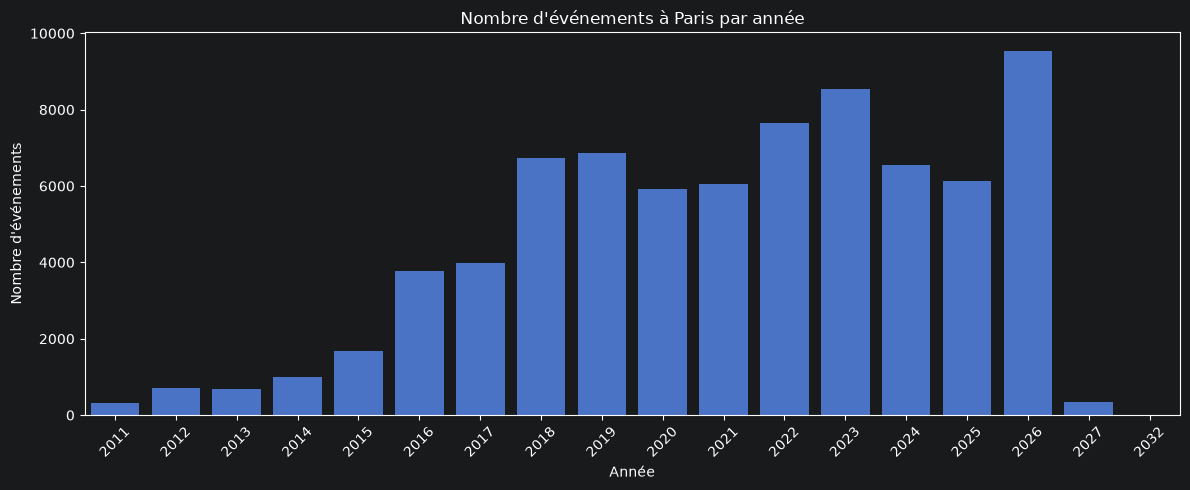

In [6]:
# Conversion en datetime
df["firstdate_begin"] = pd.to_datetime(
    df["firstdate_begin"],
    errors="coerce"
)

# Regrouper par année
events_by_year = (
    df.groupby(df["firstdate_begin"].dt.year)
    .size()
    .sort_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=events_by_year.index,
    y=events_by_year.values
)

plt.title("Nombre d'événements à Paris par année")
plt.xlabel("Année")
plt.ylabel("Nombre d'événements")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
events = filter_events(df, min_date)

print("Avant :", df.shape)
print("Après :", events.shape)

events.to_csv(
    f"{datas_folder}/events_clean.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

print("Tous les UUID sont uniques :", df["uid"].is_unique)
print(df.columns.tolist())

Avant : (76491, 56)
Après : (11234, 56)
Tous les UUID sont uniques : True
['uid', 'slug', 'canonicalurl', 'title_fr', 'description_fr', 'longdescription_fr', 'conditions_fr', 'keywords_fr', 'image', 'imagecredits', 'thumbnail', 'originalimage', 'updatedat', 'daterange_fr', 'firstdate_begin', 'firstdate_end', 'lastdate_begin', 'lastdate_end', 'timings', 'accessibility', 'accessibility_label_fr', 'location_uid', 'location_coordinates', 'location_name', 'location_address', 'location_district', 'location_insee', 'location_postalcode', 'location_city', 'location_department', 'location_region', 'location_countrycode', 'location_image', 'location_imagecredits', 'location_phone', 'location_website', 'location_links', 'location_tags', 'location_description_fr', 'location_access_fr', 'attendancemode', 'onlineaccesslink', 'status', 'age_min', 'age_max', 'originagenda_title', 'originagenda_uid', 'contributor_email', 'contributor_contactnumber', 'contributor_contactname', 'contributor_contactpositi